In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Circle, Wedge, Polygon, Patch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.projections.polar import PolarAxes

plt.rcParams.update({
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'DejaVu Sans'],
    'axes.unicode_minus': False,
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#DADCE0',
    'axes.labelcolor': '#3C4043',
    'xtick.color': '#5F6368',
    'ytick.color': '#5F6368',
    'text.color': '#202124',
})

C_NAVY = '#132B5E'
C_BLUE = '#2F6BFF'
C_TEAL = '#00B39F'
C_GOLD = '#F2A33A'
C_TEXT = '#202124'
C_SUB = '#8A94A6'

SAVE = False
OUT_DIR = 'charts_png'


# ================= 通用工具 =================
def clean_ax(ax, grid='y', left=True, bottom=True):
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.spines['left'].set_visible(left)
    ax.spines['bottom'].set_visible(bottom)
    if left:
        ax.spines['left'].set_color('#DADCE0')
    if bottom:
        ax.spines['bottom'].set_color('#C9CED6')
    if grid:
        ax.grid(axis=grid, color='#EEF1F6', linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=8)


def titles(ax, title, sub, pad=30):
    ax.set_title(title, loc='left', fontsize=17, fontweight='bold', color=C_TEXT, pad=pad)
    ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=10.5, color=C_SUB)


def unit_px(ax):
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    return bb.width / max(abs(x1 - x0), 1e-9), bb.height / max(abs(y1 - y0), 1e-9)


def rounded_path(x, y, w, h, rx=0.0, ry=None, corners='all', ax=None):
    if ry is None:
        if ax is not None and rx > 0:
            px_x, px_y = unit_px(ax)
            ry = rx * px_x / px_y
        else:
            ry = rx
    rx = min(rx, abs(w) / 2)
    ry = min(ry, abs(h) / 2 if corners == 'all' else abs(h))
    k = 0.5523
    V, C = [], []

    def mv(p):
        V.append(p); C.append(Path.MOVETO)

    def ln(p):
        V.append(p); C.append(Path.LINETO)

    def cu(p1, p2, p3):
        V.extend([p1, p2, p3]); C.extend([Path.CURVE4] * 3)

    x2, y2 = x + w, y + h
    rb = ry if corners == 'all' else 0.0
    mv((x, y + rb))
    ln((x, y2 - ry))
    cu((x, y2 - ry + k * ry), (x + rx - k * rx, y2), (x + rx, y2))
    ln((x2 - rx, y2))
    cu((x2 - rx + k * rx, y2), (x2, y2 - ry + k * ry), (x2, y2 - ry))
    ln((x2, y + rb))
    if rb:
        cu((x2, y + rb - k * rb), (x2 - rx + k * rx, y), (x2 - rx, y))
        ln((x + rx, y))
        cu((x + rx - k * rx, y), (x, y + rb - k * rb), (x, y + rb))
    else:
        ln((x, y))
    V.append(V[0]); C.append(Path.CLOSEPOLY)
    return Path(V, C)


def gradient_fill(ax, path, c1, c2, extent, direction='v', zorder=3, alpha=1.0):
    cmap = LinearSegmentedColormap.from_list('grad', [c1, c2])
    g = np.linspace(0, 1, 256)
    img = g.reshape(-1, 1) if direction == 'v' else g.reshape(1, -1)
    im = ax.imshow(img, extent=extent, origin='lower', aspect='auto',
                   cmap=cmap, alpha=alpha, zorder=zorder, interpolation='bilinear')
    clip = PathPatch(path, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(clip)
    im.set_clip_path(clip)
    return im


def gradient_arc(ax, r, t1, t2, lw, c1, c2, n=220, zorder=3, alpha=1.0):
    """带渐变的圆弧：小线段 + 圆头笔触，拼接处自然过渡。"""
    ts = np.linspace(t1, t2, n)
    cmap = LinearSegmentedColormap.from_list('arc', [c1, c2])
    for i in range(n - 1):
        tt = np.radians(ts[i:i + 2])
        ax.plot(r * np.cos(tt), r * np.sin(tt), color=cmap(i / (n - 2)),
                lw=lw, alpha=alpha, solid_capstyle='round', zorder=zorder)


def finish(fig, name):
    if SAVE:
        os.makedirs(OUT_DIR, exist_ok=True)
        fig.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', facecolor='white')
    plt.show()

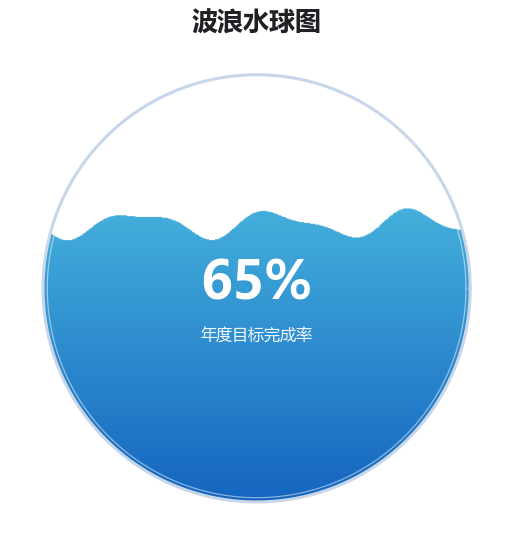

In [2]:
def wave_ball(ax, pct, c_top='#5AD1E8', c_bottom='#1565C0'):
    n = 500
    X, Y = np.meshgrid(np.linspace(-1, 1, n), np.linspace(-1, 1, n))
    level = -1 + 2 * pct
    # 两条不同频率、不同相位的正弦波叠加 → 更像真实水面
    surf = (level
            + 0.055 * np.sin(3.1 * np.pi * X + 0.7)
            + 0.022 * np.sin(5.7 * np.pi * X + 1.9))
    inside = (X ** 2 + Y ** 2) <= 1.0
    water = inside & (Y <= surf)

    t = (Y + 1) / 2                                   # 0=底部 1=顶部
    c1, c2 = np.array(mpl.colors.to_rgb(c_top)), np.array(mpl.colors.to_rgb(c_bottom))
    rgb = c2[None, None, :] * (1 - t[..., None]) + c1[None, None, :] * t[..., None]
    img = np.dstack([rgb, water.astype(float)])
    ax.imshow(img, extent=(-1, 1, -1, 1), origin='lower', zorder=2, interpolation='bilinear')

    # 玻璃质感：外圈 + 高光
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color='#C7D6E8', lw=2, zorder=5)
    ax.plot(np.cos(th) * 0.98, np.sin(th) * 0.98, color='white', lw=0.8, alpha=0.5, zorder=5)
    arc = np.linspace(np.radians(100), np.radians(148), 60)
    ax.plot(0.86 * np.cos(arc), 0.86 * np.sin(arc), color='white', lw=5, alpha=0.4,
            solid_capstyle='round', zorder=6)

    ax.text(0, 0.02, f'{pct:.0%}', ha='center', va='center', fontsize=34,
            fontweight='bold', color='white', zorder=8)
    ax.text(0, -0.22, '年度目标完成率', ha='center', va='center', fontsize=10.5,
            color='white', alpha=0.95, zorder=8)
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect('equal')
    ax.axis('off')


fig, ax = plt.subplots(figsize=(5.8, 5.8))
wave_ball(ax, 0.65)
ax.set_title('波浪水球图', fontsize=17, fontweight='bold', color=C_TEXT, pad=8)
finish(fig, 'case16_wave_ball')

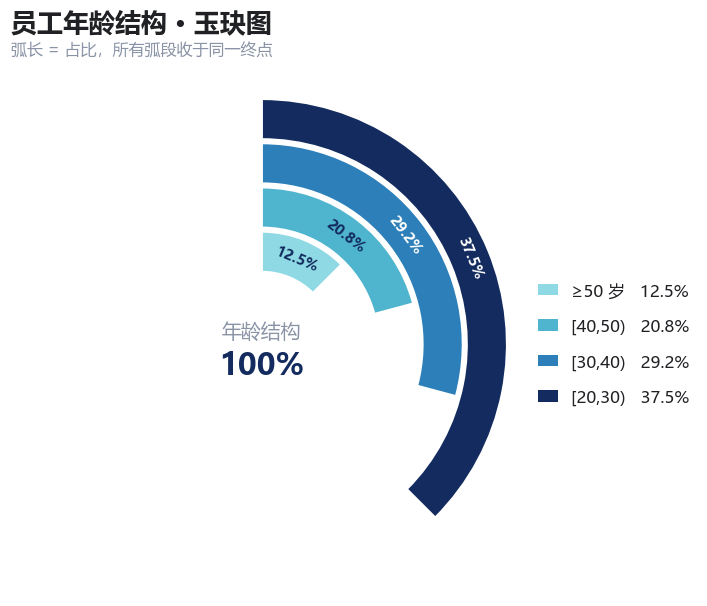

In [3]:
df17 = pd.DataFrame({'年龄': ['≥50 岁', '[40,50)', '[30,40)', '[20,30)'],
                     '占比': [0.125, 0.2083, 0.2917, 0.375]})

fig = plt.figure(figsize=(7.6, 6.2))
ax = fig.add_axes([0.06, 0.06, 0.6, 0.86])
ax.set_xlim(-1.18, 1.18)
ax.set_ylim(-1.18, 1.18)
ax.set_aspect('equal')
ax.axis('off')

colors = ['#8ED9E3', '#4FB4CE', '#2C7FB8', '#132B5E']
r0, width, gap = 0.34, 0.19, 0.018
end = 90.0                                     # 所有弧段都收在 12 点钟方向

for i, row in df17.iterrows():
    r_in = r0 + i * (width + gap)
    sweep = row['占比'] * 360
    w = Wedge((0, 0), r_in + width, end - sweep, end, width=width,
              facecolor=colors[i], edgecolor='white', linewidth=1.5, zorder=3)
    ax.add_patch(w)
    mid = np.radians(end - sweep / 2)
    ax.text((r_in + width / 2) * np.cos(mid), (r_in + width / 2) * np.sin(mid),
            f'{row["占比"]:.1%}', ha='center', va='center', fontsize=9.5,
            color='white' if i >= 2 else C_NAVY, fontweight='bold', rotation=-sweep / 2, zorder=4)

ax.text(0, 0.06, '年龄结构', ha='center', va='center', fontsize=13, color=C_SUB)
ax.text(0, -0.10, f'{df17["占比"].sum():.0%}', ha='center', va='center',
        fontsize=20, fontweight='bold', color=C_NAVY)

handles = [Patch(fc=colors[i], label=f'{row["年龄"]}   {row["占比"]:.1%}')
           for i, row in df17.iterrows()]
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5),
          frameon=False, fontsize=11, handlelength=1.2, labelspacing=1.1)

fig.suptitle('员工年龄结构 · 玉玦图', x=0.06, ha='left', fontsize=17, fontweight='bold', color=C_TEXT)
fig.text(0.06, 0.915, '弧长 = 占比，所有弧段收于同一终点', fontsize=10.5, color=C_SUB)
finish(fig, 'case17_jade_ring')

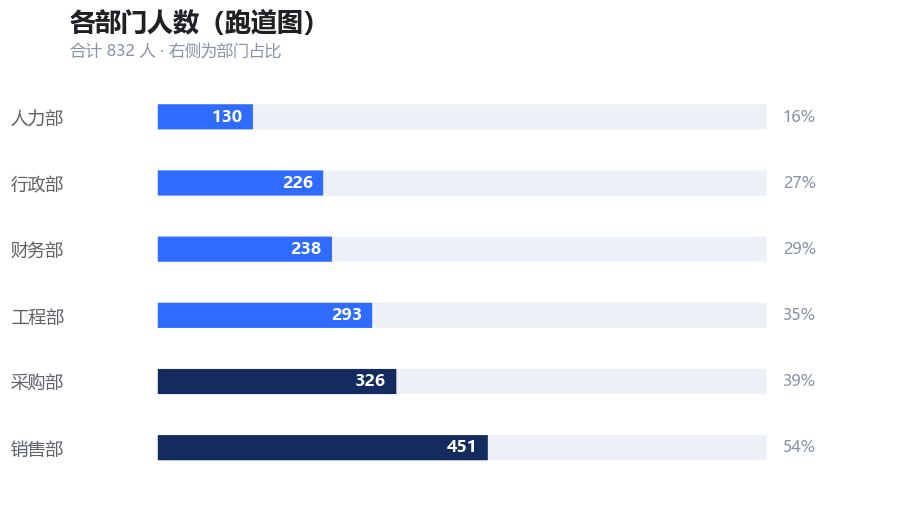

In [4]:
df18 = pd.DataFrame({'部门': ['人力部', '行政部', '财务部', '工程部', '采购部', '销售部'],
                     '人数': [130, 226, 238, 293, 326, 451]})
total = 832

fig, ax = plt.subplots(figsize=(9.6, 5.0))
ax.set_xlim(-120, total * 1.2)
ax.set_ylim(-0.7, len(df18) - 0.3)
ax.invert_yaxis()

for i, row in df18.iterrows():
    ax.add_patch(PathPatch(rounded_path(0, i - 0.19, total, 0.38, rx=0.19, ax=ax),
                           fc='#EDF1F7', ec='none', zorder=2))
    ax.add_patch(PathPatch(rounded_path(0, i - 0.19, row['人数'], 0.38, rx=0.19, ax=ax),
                           fc=C_BLUE if i < 4 else C_NAVY, ec='none', zorder=3))
    ax.text(row['人数'] - 14, i, f'{row["人数"]}', ha='right', va='center',
            fontsize=11, fontweight='bold', color='white', zorder=4)
    ax.text(total + 22, i, f'{row["人数"] / total:.0%}', ha='left', va='center',
            fontsize=10.5, color=C_SUB)

ax.set_yticks(range(len(df18)))
ax.set_yticklabels(df18['部门'], fontsize=11.5)
ax.set_xticks([])
clean_ax(ax, grid=None, left=False, bottom=False)
ax.tick_params(axis='y', pad=4)
titles(ax, '各部门人数（跑道图）', f'合计 {total} 人 · 右侧为部门占比', pad=26)
finish(fig, 'case18_runway_bar')

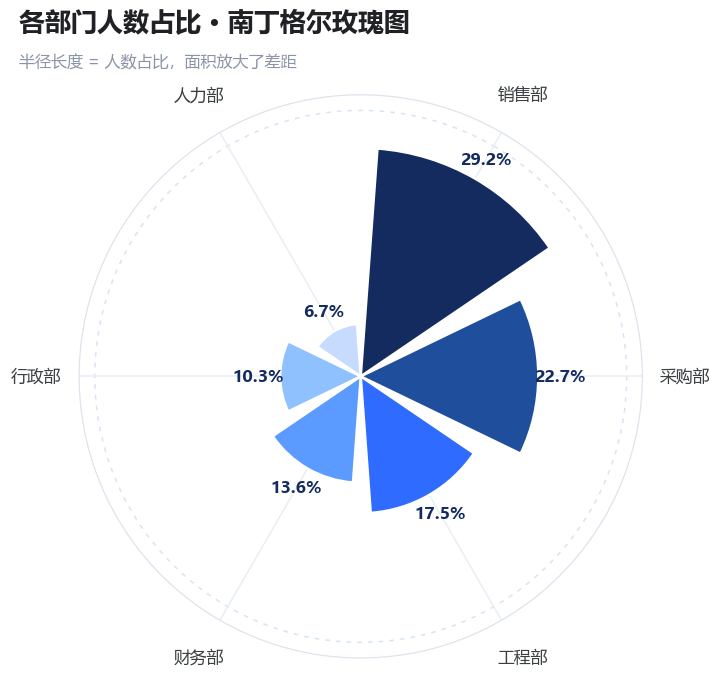

In [5]:
df19 = pd.DataFrame({'部门': ['销售部', '采购部', '工程部', '财务部', '行政部', '人力部'],
                     '人数占比': [0.292, 0.227, 0.175, 0.136, 0.103, 0.067]})

fig = plt.figure(figsize=(7.4, 6.4))
ax = fig.add_axes([0.08, 0.06, 0.84, 0.8], projection='polar')
n = len(df19)
theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
colors = ['#132B5E', '#1F4E9C', '#2F6BFF', '#5B9BFF', '#8FC1FF', '#C7DBFF']

ax.bar(theta, df19['人数占比'], width=2 * np.pi / n * 0.86,
       color=colors, edgecolor='white', linewidth=1.6, zorder=3)
ax.set_theta_offset(np.pi / 2 - np.pi / n)
ax.set_theta_direction(-1)
ax.set_ylim(0, 0.36)
ax.set_yticks([])
ax.set_xticks(theta)
ax.set_xticklabels([])
ax.grid(color='#E9EEF6', lw=1)
ax.spines['polar'].set_color('#DDE3EC')
th = np.linspace(0, 2 * np.pi, 400)
ax.plot(th, np.full_like(th, 0.34), color='#D8E4F5', lw=1, ls=(0, (3, 4)), zorder=1)

for t, v, name in zip(theta, df19['人数占比'], df19['部门']):
    ax.text(t, v + 0.028, f'{v:.1%}', ha='center', va='center',
            fontsize=11, fontweight='bold', color=C_NAVY)
    ax.text(t, 0.415, name, ha='center', va='center', fontsize=11, color='#3C4043')

fig.suptitle('各部门人数占比 · 南丁格尔玫瑰图', x=0.08, ha='left',
             fontsize=17, fontweight='bold', color=C_TEXT)
fig.text(0.08, 0.9, '半径长度 = 人数占比，面积放大了差距', fontsize=10.5, color=C_SUB)
finish(fig, 'case19_nightingale_pie')

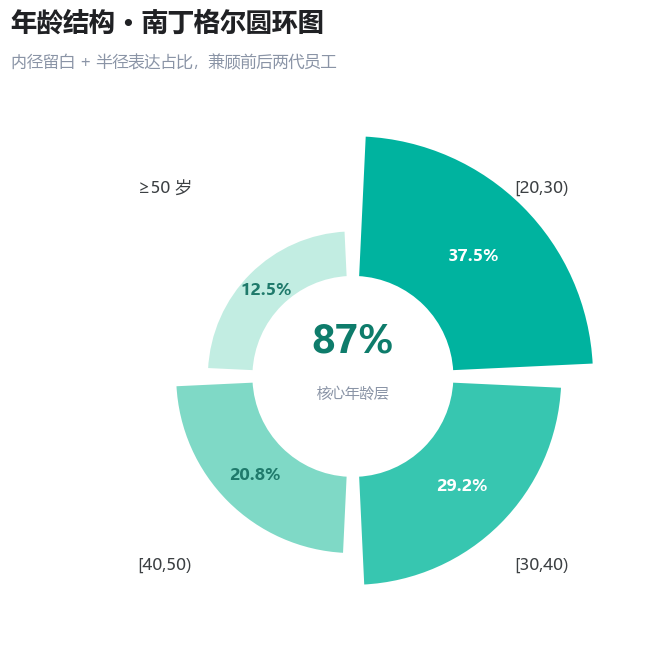

In [6]:
df20 = pd.DataFrame({'年龄': ['[20,30)', '[30,40)', '[40,50)', '≥50 岁'],
                     '人数占比': [0.375, 0.2917, 0.2083, 0.125]})

fig = plt.figure(figsize=(7.4, 6.4))
ax = fig.add_axes([0.08, 0.06, 0.84, 0.8], projection='polar')
n = len(df20)
theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
colors = ['#00B39F', '#37C6B0', '#7FD9C6', '#C2EDE2']

ax.bar(theta, df20['人数占比'], width=2 * np.pi / n * 0.94, bottom=0.26,
       color=colors, edgecolor='white', linewidth=2, zorder=3)
ax.set_theta_offset(np.pi / 2 - np.pi / n)
ax.set_theta_direction(-1)
ax.set_ylim(0, 0.74)
ax.set_yticks([])
ax.set_xticks(theta)
ax.set_xticklabels([])
ax.grid(False)
ax.spines['polar'].set_visible(False)

for i, (t, v, name) in enumerate(zip(theta, df20['人数占比'], df20['年龄'])):
    ax.text(t, 0.26 + v / 2, f'{v:.1%}', ha='center', va='center',
            fontsize=11, fontweight='bold',
            color='white' if i < 2 else '#1F7A6B', zorder=5)
    ax.text(t, 0.70, name, ha='center', va='center', fontsize=11, color='#3C4043')

ax.annotate('87%', xy=(0, 0), xytext=(0, 10), textcoords='offset points',
            ha='center', va='bottom', fontsize=25, fontweight='bold', color='#0E7C6B')
ax.annotate('核心年龄层', xy=(0, 0), xytext=(0, -6), textcoords='offset points',
            ha='center', va='top', fontsize=9.5, color=C_SUB)

fig.suptitle('年龄结构 · 南丁格尔圆环图', x=0.08, ha='left',
             fontsize=17, fontweight='bold', color=C_TEXT)
fig.text(0.08, 0.9, '内径留白 + 半径表达占比，兼顾前后两代员工', fontsize=10.5, color=C_SUB)
finish(fig, 'case20_nightingale_donut')

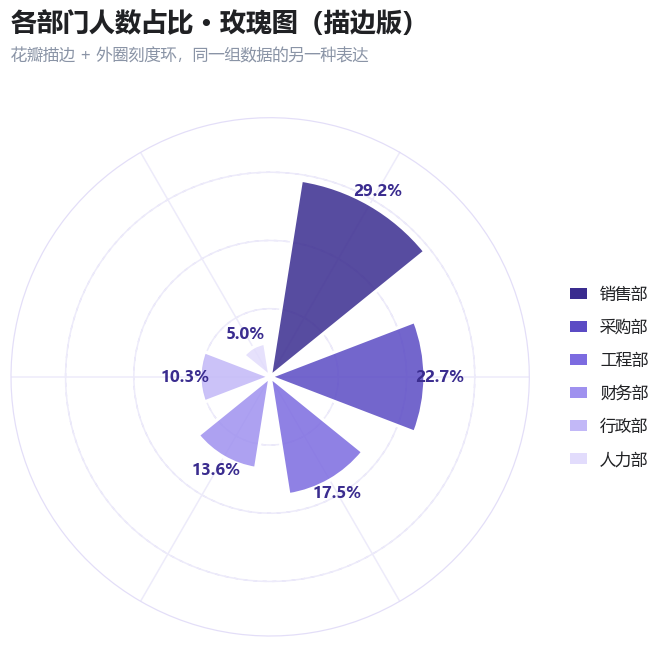

In [7]:
df21 = pd.DataFrame({'部门': ['销售部', '采购部', '工程部', '财务部', '行政部', '人力部'],
                     '人数占比': [0.292, 0.227, 0.175, 0.136, 0.103, 0.05]})

fig = plt.figure(figsize=(7.6, 6.4))
ax = fig.add_axes([0.07, 0.07, 0.62, 0.78], projection='polar')
n = len(df21)
theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
colors = ['#3A2C8F', '#5B4BC4', '#7C6BE0', '#9F91EF', '#C2B8F7', '#E2DCFC']

bars = ax.bar(theta, df21['人数占比'], width=2 * np.pi / n * 0.7,
              color=[mpl.colors.to_rgba(c, 0.85) for c in colors],
              edgecolor='white', linewidth=2.2, zorder=3)
ax.set_theta_offset(np.pi / 2 - np.pi / n)
ax.set_theta_direction(-1)
ax.set_ylim(0, 0.38)
ax.set_yticks([0.1, 0.2, 0.3])
ax.set_yticklabels([])
ax.set_xticks(theta)
ax.set_xticklabels([])
ax.grid(color='#EDEBFA', lw=1)
ax.spines['polar'].set_color('#E3DEF8')

# 外圈刻度环：每 10% 一个参考圆
for lv in [0.1, 0.2, 0.3]:
    th = np.linspace(0, 2 * np.pi, 300)
    ax.plot(th, np.full_like(th, lv), color='#D8D2F5', lw=0.9, ls=(0, (3, 4)), zorder=1)

for t, v in zip(theta, df21['人数占比']):
    ax.text(t, v + 0.022, f'{v:.1%}', ha='center', va='center',
            fontsize=10.5, fontweight='bold', color='#3A2C8F')

handles = [Patch(fc=colors[i], label=df21['部门'].iloc[i]) for i in range(n)]
ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.05, 0.5),
          frameon=False, fontsize=10.5, handlelength=1.1, labelspacing=1.0)

fig.suptitle('各部门人数占比 · 玫瑰图（描边版）', x=0.07, ha='left',
             fontsize=17, fontweight='bold', color=C_TEXT)
fig.text(0.07, 0.91, '花瓣描边 + 外圈刻度环，同一组数据的另一种表达', fontsize=10.5, color=C_SUB)
finish(fig, 'case21_nightingale_petal')

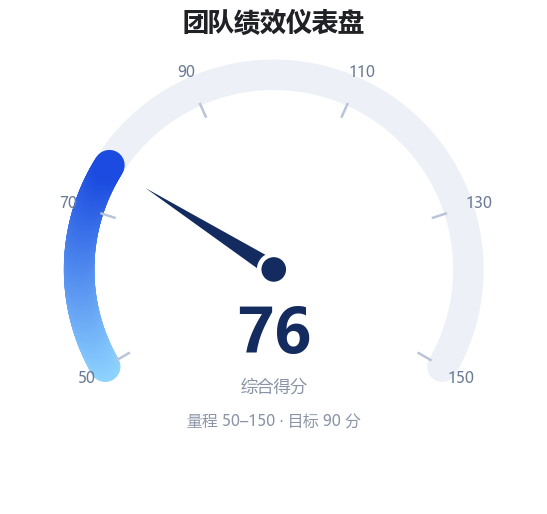

In [8]:
value, vmin, vmax = 76, 50, 150
a_start, a_end = 210, -30          # 从左下扫到右下，共 240°

fig, ax = plt.subplots(figsize=(6.6, 5.4))
ax.set_xlim(-1.35, 1.35)
ax.set_ylim(-1.2, 1.15)
ax.set_aspect('equal')
ax.axis('off')

# 底弧
track = np.linspace(a_start, a_end, 300)
ax.plot(np.cos(np.radians(track)), np.sin(np.radians(track)),
        color='#EDF1F7', lw=20, solid_capstyle='round', zorder=2)
# 数值弧（渐变）
frac = (value - vmin) / (vmax - vmin)
gradient_arc(ax, 1.0, a_start, a_start - 240 * frac, 20, '#8FD4FF', '#1B4BE0', n=200, zorder=3)

# 刻度
ticks = np.arange(vmin, vmax + 1, 20)
for t in ticks:
    ang = np.radians(a_start - 240 * (t - vmin) / (vmax - vmin))
    r1, r2 = 0.86, 0.93
    ax.plot([r1 * np.cos(ang), r2 * np.cos(ang)], [r1 * np.sin(ang), r2 * np.sin(ang)],
            color='#B9C4D6', lw=1.6, zorder=4)
    ax.text(1.11 * np.cos(ang), 1.11 * np.sin(ang), str(t), ha='center', va='center',
            fontsize=10, color='#6B7B95')

# 指针
ang = np.radians(a_start - 240 * frac)
tip = (0.78 * np.cos(ang), 0.78 * np.sin(ang))
base_l = (0.045 * np.cos(ang + np.pi / 2), 0.045 * np.sin(ang + np.pi / 2))
base_r = (0.045 * np.cos(ang - np.pi / 2), 0.045 * np.sin(ang - np.pi / 2))
ax.add_patch(Polygon([tip, base_l, base_r], closed=True, fc=C_NAVY, ec='none', zorder=6))
ax.add_patch(Circle((0, 0), 0.075, fc=C_NAVY, ec='white', lw=3, zorder=7))

ax.text(0, -0.34, f'{value}', ha='center', va='center', fontsize=40,
        fontweight='bold', color=C_NAVY)
ax.text(0, -0.6, '综合得分', ha='center', va='center', fontsize=11, color=C_SUB)
ax.text(0, -0.78, f'量程 {vmin}–{vmax} · 目标 90 分', ha='center', va='center',
        fontsize=10, color=C_SUB)

ax.set_title('团队绩效仪表盘', fontsize=17, fontweight='bold', color=C_TEXT, pad=10)
finish(fig, 'case22_gauge')

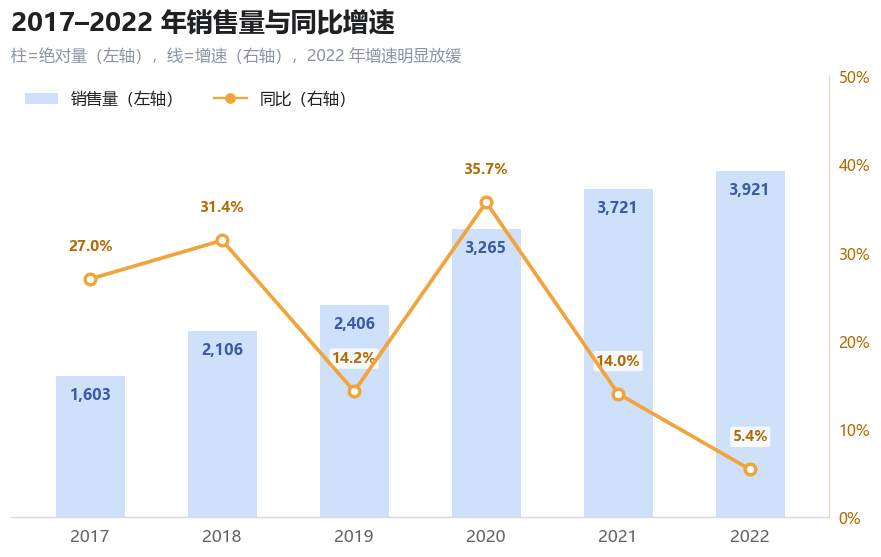

In [9]:
df23 = pd.DataFrame({'年份': ['2017', '2018', '2019', '2020', '2021', '2022'],
                     '销售量': [1603, 2106, 2406, 3265, 3721, 3921],
                     '同比': [0.27, 0.3138, 0.1425, 0.357, 0.1397, 0.0537]})

fig, ax = plt.subplots(figsize=(9.6, 5.2))
x = np.arange(len(df23))
ax.set_xlim(-0.6, len(df23) - 0.4)
ax.set_ylim(0, 5000)

bars = ax.bar(x, df23['销售量'], width=0.52, color='#CFE0FB', edgecolor='none', zorder=2)
for xi, v in zip(x, df23['销售量']):
    ax.text(xi, v - 120, f'{v:,}', ha='center', va='top', fontsize=10,
            color='#3B5BA5', fontweight='bold', zorder=6)

ax2 = ax.twinx()
ax2.plot(x, df23['同比'], color=C_GOLD, lw=2.4, marker='o', ms=7, mfc='white',
         mew=2.2, zorder=5, label='同比')
for xi, v in zip(x, df23['同比']):
    ax2.text(xi, v + 0.028, f'{v:.1%}', ha='center', va='bottom', fontsize=9.5,
             color='#B26B00', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))

ax2.set_ylim(0, 0.50)
ax2.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax2.spines['top'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.spines['right'].set_color('#F3D6AE')
ax2.tick_params(axis='y', colors='#B26B00', length=0, pad=6)

ax.set_xticks(x)
ax.set_xticklabels(df23['年份'], fontsize=11)
ax.set_yticks([])
clean_ax(ax, grid='y', left=False)

ax.legend(handles=[Patch(fc='#CFE0FB', label='销售量（左轴）'),
                   plt.Line2D([], [], color=C_GOLD, marker='o', label='同比（右轴）')],
          loc='upper left', ncol=2, frameon=False, fontsize=10.5)
titles(ax, '2017–2022 年销售量与同比增速', '柱=绝对量（左轴），线=增速（右轴），2022 年增速明显放缓', pad=30)
finish(fig, 'case23_bar_line')